# cv2（选学讲义·第二讲）·「✍️ 练习」参考答案

> 配套 `cv2.ipynb` 的 **7 组练习**（第 1～6 章 + 第 4 章的综合练习）。
> **先自己写一遍，再来对**。
>
> **怎么用**：每章先是「思路 / 结论」，后面是**能直接跑的代码**，
> 输出就是我在自己机器上跑出来的真实结果（图也留在里面）。
>
> **实测环境**：`opencv-contrib-python 5.0.0.93` + `numpy 2.4.6`
> （`cv2.ipynb` 里保存的输出是在 **OpenCV 4.13.0** 上跑的；本文件用到的 API 两版行为一致）。
>
> ⚠️ **数字只是参考**：换图、换参数数就会变。重点看「怎么想、怎么试」。
>
> 💡 本讲义有自己的 `bg_threshold()`（见第 0 章），下面会用到，先把它抄进来。

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams['font.sans-serif'] = ['Microsoft YaHei', 'SimHei', 'WenQuanYi Micro Hei', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['figure.dpi'] = 52


def bg_threshold(gray, drop=20):
    """讲义第 0 章的公共工具：从四条边估背景亮度，再往下压一点。"""
    border = np.concatenate([gray[0], gray[-1], gray[:, 0], gray[:, -1]])
    return max(int(np.median(border)) - drop, 1)


print('OpenCV', cv2.__version__, '| numpy', np.__version__)

OpenCV 5.0.0 | numpy 2.4.6


---
# 第 1 章 边缘检测（`1.5 第 1 章练习`）

**练习 1（白底图 Canny）**：把 `t1/t2` 从高往低试，看轮廓是否**闭合、干净**。
  实测 `50/150` 边缘占比 0.85%、`100/200` 0.73%、`30/90` 0.98% ——
  阈值越低边缘越多（噪声也越多）。

**练习 2（暗图为什么更难）**：`nl_galaxy` 灰度均值 135.8、**标准差 81.0**，
  但直方图是「大片中灰 + 少数高光」。
  实测直接 Canny 边缘占比 **8.93%**（一片噪声），**先高斯去噪后降到 5.34%**。
  → 暗图的预处理顺序是「**先去噪（或先提对比度）再 Canny**」。

**练习 3（Sobel ksize）**：`ksize` 越大，核越大、参与差分的邻域越宽，
  噪声被放大的程度急剧上升。实测**绝对值均值** 3→4.71、5→68.10、**7→1036.95**，
  `max` 从 853 飙到 126983。→ **除非图很干净，`ksize` 用 3。**

**练习 4（Laplacian 先高斯）**：实测绝对值均值 原图 1.59 → **先高斯 0.78**。
  Laplacian 是**二阶导**，对噪声极其敏感（噪声被平方级放大），
  所以标准做法是先用高斯平滑（这就是 **LoG，高斯拉普拉斯**）。

**练习 5（思考）非极大值抑制解决什么**：Canny 第 1 步算出的梯度幅值图里，
  一条边缘会形成**好几像素宽的山脊**。NMS 只保留山脊上**梯度最大**的那个像素，
  把边缘"削"成**单像素宽**。去掉它 → 边缘变成**又粗又糊的带子**，
  而且因为一个边缘被算成很多条，后续 Hough 变换会疯狂重复投票。

**练习 6（思考）为什么需要滞后连接**：单阈值只有两种选择：
  高阈值 → 只留下最强的一段段**碎线**（弱边缘全丢，轮廓断开）；
  低阈值 → 噪声全进来了。
  双阈值 + 滞后连接 = 「**高阈值定可靠的种子，低阈值沿弱边缘把种子连起来**」，
  这样既不断线、又不引入孤立噪声。

=== 1.1 白底图 nl_think.png 的 Canny ===
  Canny( 30, 90) -> 边缘占比 0.98%
  Canny( 50,150) -> 边缘占比 0.85%
  Canny(100,200) -> 边缘占比 0.73%
  ↑ 阈值越低，边缘越多（噪声也越多）；要挑"轮廓闭合但不脏"的那组

=== 1.2 暗图 nl_galaxy.png ===
  灰度均值=135.8 标准差=81.0
  直接 Canny           边缘占比 8.93%  <- 一片噪声
  先高斯去噪再 Canny   边缘占比 5.34%
  灰度分位 p50=127 p90=227 p99=233  <- 大片中灰 + 少数高光

=== 1.3 Sobel 的 ksize ===
  ksize=3 -> |响应|均值=    4.71   max=853
  ksize=5 -> |响应|均值=   68.10   max=9816
  ksize=7 -> |响应|均值= 1036.95   max=126983
  ↑ ksize 越大噪声放大越猛 —— 除非图很干净，用 3

=== 1.4 Laplacian：原图 vs 先高斯 ===
  原图    |Laplacian| 均值 = 1.59
  先高斯  |Laplacian| 均值 = 0.78   <- 噪声被压下去
  ↑ 二阶导对噪声极敏感，标准做法是 LoG（高斯拉普拉斯）


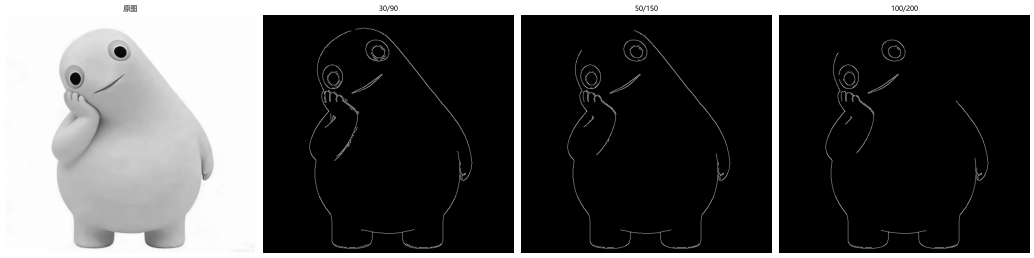

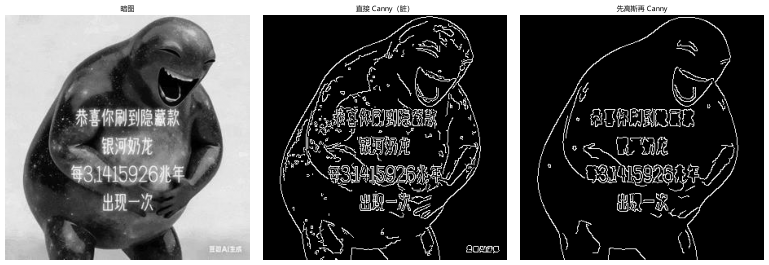

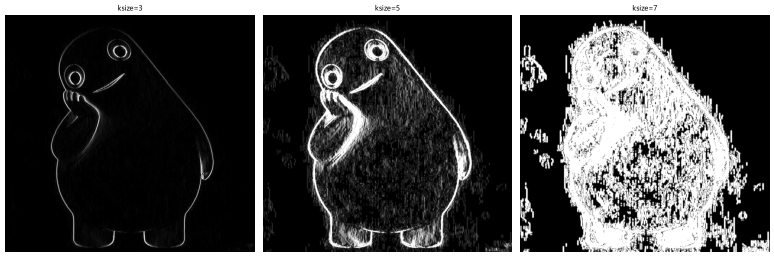

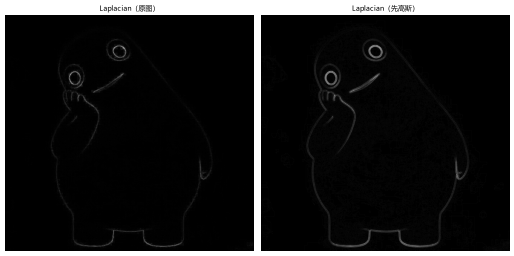

In [2]:
print('=== 1.1 白底图 nl_think.png 的 Canny ===')
think = cv2.imread('res/nl_think.png', cv2.IMREAD_GRAYSCALE)
outs = []
for t1, t2 in [(30, 90), (50, 150), (100, 200)]:
    e = cv2.Canny(think, t1, t2)
    outs.append(e)
    print(f'  Canny({t1:3d},{t2:3d}) -> 边缘占比 {100*np.count_nonzero(e)/e.size:.2f}%')
print('  ↑ 阈值越低，边缘越多（噪声也越多）；要挑"轮廓闭合但不脏"的那组')
show_img(think, *outs, titles=['原图', '30/90', '50/150', '100/200'])

print()
print('=== 1.2 暗图 nl_galaxy.png ===')
gal = cv2.imread('res/nl_galaxy.png', cv2.IMREAD_GRAYSCALE)
print(f'  灰度均值={gal.mean():.1f} 标准差={gal.std():.1f}')
e1 = cv2.Canny(gal, 100, 200)
e2 = cv2.Canny(cv2.GaussianBlur(gal, (5, 5), 0), 100, 200)
print(f'  直接 Canny           边缘占比 {100*np.count_nonzero(e1)/e1.size:.2f}%  <- 一片噪声')
print(f'  先高斯去噪再 Canny   边缘占比 {100*np.count_nonzero(e2)/e2.size:.2f}%')
print(f'  灰度分位 p50={np.percentile(gal,50):.0f} p90={np.percentile(gal,90):.0f} '
      f'p99={np.percentile(gal,99):.0f}  <- 大片中灰 + 少数高光')
show_img(gal, e1, e2, titles=['暗图', '直接 Canny（脏）', '先高斯再 Canny'])

print()
print('=== 1.3 Sobel 的 ksize ===')
for ks in [3, 5, 7]:
    s = cv2.Sobel(think, cv2.CV_32F, 1, 0, ksize=ks)
    print(f'  ksize={ks} -> |响应|均值={np.abs(s).mean():8.2f}   max={s.max():.0f}')
print('  ↑ ksize 越大噪声放大越猛 —— 除非图很干净，用 3')
show_img(*[cv2.convertScaleAbs(cv2.Sobel(think, cv2.CV_32F, 1, 0, ksize=k)) for k in (3, 5, 7)],
         titles=['ksize=3', 'ksize=5', 'ksize=7'])

print()
print('=== 1.4 Laplacian：原图 vs 先高斯 ===')
lap = cv2.Laplacian(think, cv2.CV_32F)
lapg = cv2.Laplacian(cv2.GaussianBlur(think, (5, 5), 0), cv2.CV_32F)
print(f'  原图    |Laplacian| 均值 = {np.abs(lap).mean():.2f}')
print(f'  先高斯  |Laplacian| 均值 = {np.abs(lapg).mean():.2f}   <- 噪声被压下去')
print('  ↑ 二阶导对噪声极敏感，标准做法是 LoG（高斯拉普拉斯）')
show_img(cv2.convertScaleAbs(lap), cv2.convertScaleAbs(lapg),
         titles=['Laplacian（原图）', 'Laplacian（先高斯）'])

---
# 第 2 章 二值化与阈值（`✍️ 练习`）

**练习 1**：只有 `BINARY` / `BINARY_INV` 是真正的 0/255 二值图
  （唯一值个数 = 2）。`TRUNC` 取值只到 **127**、`TOZERO` 保留灰度、
  `TOZERO_INV` 只到 127 —— **它们的输出里根本没有 255**，
  所以对它们算"白像素占比"是**没有意义的**。

**练习 2**：换成 `THRESH_BINARY` 后**黑白完全对调**：
  白底变白、物体变黑。处理白底图时这就是**拿到了"背景"的掩膜**，
  后面抠图会把主体抠掉。

**练习 3**：`OTSU = 152`，`bg_threshold() = 232`（灰度中位数 183）。
  **白底抠图用 `bg_threshold`** —— 阈值必须落在目标和背景之间的空档（≈230）。
  OTSU 失效的原因：白底占了 60%+，直方图偏态，不满足"双峰且两峰相当"。

**练习 4**：`blockSize` 越大越接近全局阈值；`C` 越大判黑越苛刻。
  这张图整体偏亮，实测前景占比 90%~99%，**光靠一个 blockSize 通吃不了，要配合 ROI**。
  ⚠️ 一定要**看掩膜图**，不能只看占比。

**练习 5**：`blockSize` 取偶数直接报
  `(-215:Assertion failed) blockSize % 2 == 1 && blockSize > 1` ——
  偶数边长没有唯一的中心像素。

**练习 6（思考）**：彩色图按颜色切分用 **`cv2.inRange`**。
  `threshold` 只吃单通道；先转灰度就把颜色信息丢了，
  「红色」和「同亮度的灰」在灰度图里分不开。

=== 2.1 五种 type：为什么 TRUNC/TOZERO 的"白像素占比"没意义 ===
  BINARY       非零占比= 95.6%  取值=0~255  唯一值=2
  BINARY_INV   非零占比=  4.4%  取值=0~255  唯一值=2
  TRUNC        非零占比=100.0%  取值=0~127  唯一值=128
  TOZERO       非零占比= 95.6%  取值=0~255  唯一值=129
  TOZERO_INV   非零占比=  4.4%  取值=0~127  唯一值=128
  ↑ 只有前两个的唯一值是 2（真正的 0/255）；后三个里根本没有 255

=== 2.3 OTSU vs bg_threshold（nl_santa）===
  OTSU = 152
  bg_threshold() = 232     灰度中位数 = 183
  ↑ 白底抠图用 bg_threshold：阈值得落在目标和背景之间的空档

=== 2.4 nl_hd17 的自适应阈值 ===
  blockSize= 11 C= 5 -> 前景占比  96.8%
  blockSize= 11 C=10 -> 前景占比  99.6%
  blockSize= 31 C= 5 -> 前景占比  93.0%
  blockSize= 31 C=10 -> 前景占比  97.7%
  blockSize= 61 C= 5 -> 前景占比  90.7%
  blockSize= 61 C=10 -> 前景占比  95.7%
  ↑ 数字只能告诉你"白了多少"，看不出"白得对不对" —— 要看图

=== 2.5 blockSize 取偶数 ===
  报错： OpenCV(5.0.0) D:\a\opencv-python\opencv-python\opencv\modules\imgproc\src\thresh.cpp:1908: error: (-215:Assertion failed) blockSize % 2 == 1 && blockSize > 1 in function 'cv::adaptiveThreshold'
  原因：偶数边长没有唯一的中心像素

=== 2.2 换成 THRESH_BINAR

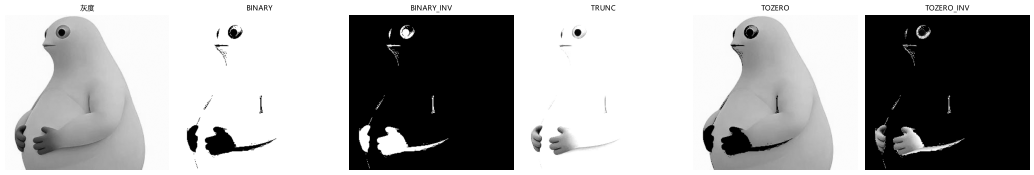

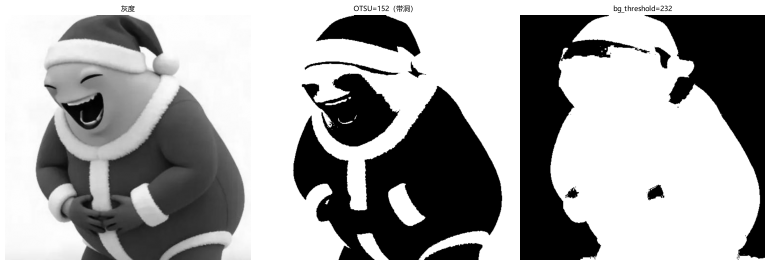

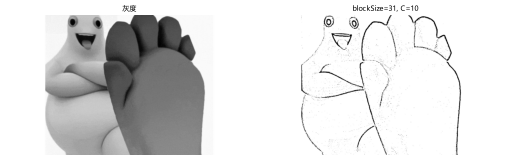

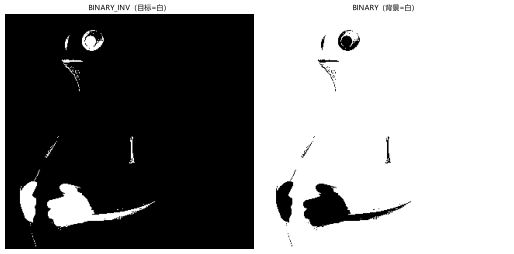

In [3]:
print('=== 2.1 五种 type：为什么 TRUNC/TOZERO 的"白像素占比"没意义 ===')
side = cv2.imread('res/nl_side.png', cv2.IMREAD_GRAYSCALE)
outs = []
for name, t in [('BINARY', cv2.THRESH_BINARY), ('BINARY_INV', cv2.THRESH_BINARY_INV),
                ('TRUNC', cv2.THRESH_TRUNC), ('TOZERO', cv2.THRESH_TOZERO),
                ('TOZERO_INV', cv2.THRESH_TOZERO_INV)]:
    _, r = cv2.threshold(side, 127, 255, t)
    outs.append(r)
    print(f'  {name:12s} 非零占比={100*np.count_nonzero(r)/r.size:5.1f}%  '
          f'取值={int(r.min())}~{int(r.max())}  唯一值={len(np.unique(r))}')
print('  ↑ 只有前两个的唯一值是 2（真正的 0/255）；后三个里根本没有 255')
show_img(side, *outs, titles=['灰度', 'BINARY', 'BINARY_INV', 'TRUNC', 'TOZERO', 'TOZERO_INV'])

print()
print('=== 2.3 OTSU vs bg_threshold（nl_santa）===')
san = cv2.imread('res/nl_santa.png', cv2.IMREAD_GRAYSCALE)
t_ot, b_ot = cv2.threshold(san, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
t_bg = bg_threshold(san)
_, b_bg = cv2.threshold(san, t_bg, 255, cv2.THRESH_BINARY_INV)
print(f'  OTSU = {int(t_ot)}')
print(f'  bg_threshold() = {t_bg}     灰度中位数 = {int(np.median(san))}')
print('  ↑ 白底抠图用 bg_threshold：阈值得落在目标和背景之间的空档')
show_img(san, b_ot, b_bg, titles=['灰度', f'OTSU={int(t_ot)}（带洞）', f'bg_threshold={t_bg}'])

print()
print('=== 2.4 nl_hd17 的自适应阈值 ===')
h17 = cv2.imread('res/nl_hd17.jpg', cv2.IMREAD_GRAYSCALE)
for bs in [11, 31, 61]:
    for Cc in [5, 10]:
        ad = cv2.adaptiveThreshold(h17, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
                                   cv2.THRESH_BINARY, bs, Cc)
        print(f'  blockSize={bs:3d} C={Cc:2d} -> 前景占比 {100*np.count_nonzero(ad)/ad.size:5.1f}%')
print('  ↑ 数字只能告诉你"白了多少"，看不出"白得对不对" —— 要看图')
show_img(h17, cv2.adaptiveThreshold(h17, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
                                    cv2.THRESH_BINARY, 31, 10),
         titles=['灰度', 'blockSize=31, C=10'])

print()
print('=== 2.5 blockSize 取偶数 ===')
try:
    cv2.adaptiveThreshold(h17, 255, cv2.ADAPTIVE_THRESH_MEAN_C, cv2.THRESH_BINARY, 30, 5)
    print('  没报错')
except cv2.error as e:
    print('  报错：', str(e).strip().splitlines()[-1])
print('  原因：偶数边长没有唯一的中心像素')

print()
print('=== 2.2 换成 THRESH_BINARY ===')
_, b_inv = cv2.threshold(side, 127, 255, cv2.THRESH_BINARY_INV)
_, b_bin = cv2.threshold(side, 127, 255, cv2.THRESH_BINARY)
print('  黑白完全对调：BINARY 得到的是"背景"的掩膜，抠图会把主体抠掉')
show_img(b_inv, b_bin, titles=['BINARY_INV（目标=白）', 'BINARY（背景=白）'])

---
# 第 3 章 轮廓检测（`3.3 第 3 章练习`）

**练习 1**：`nl_question` 最大轮廓用 `approxPolyDP` 逼近，
  `eps=0.01×周长` → **13 个顶点**、`0.02` → **10 个**、`0.05` → **4 个**。
  → 顶点数**完全由 `eps` 决定**，不存在"这个形状是几边形"这样唯一正确的答案，
  要看你想表达多粗的近似。

**练习 2**：`nl_angry` 上实测 `RETR_EXTERNAL` = **1 条**，
  `RETR_LIST` / `RETR_TREE` = **5 条**。
  因为 `EXTERNAL` **只返回最外层轮廓**，内部的黑洞（眼睛、嘴巴的镂空）不算；
  `LIST` 和 `TREE` 会把内部的也返回（`TREE` 还额外给出父子层级关系，
  但**数量**和 `LIST` 一样）。

**练习 3**：`cv2.moments(c)` 拿 `m00`(面积) / `m10` / `m01`，
  质心 = `(m10/m00, m01/m00)`。实测最大轮廓质心 ≈ `(429.1, 477.4)`、面积 454194。

**练习 4 `classify_shape`**：用 `approxPolyDP` 顶点数 + **圆度**
  `4πA/P²`（圆=1）来判断。实测 `nl_question` 的最大轮廓是
  "不规则(10 边, 圆度 0.53)" —— 因为它的最大轮廓其实是**整只奶蛙的外形**，
  并不是一个几何形状。

**练习 5（思考）`CHAIN_APPROX_SIMPLE` 为什么能压缩点**：
  轮廓是**像素的 8 邻域链条**，在一条**直线段**上，中间的像素点全部共线、
  不携带任何信息。`SIMPLE` 只保留**方向发生变化的拐点**（线段两端），
  所以同一条轮廓能省下 90% 以上的点，而**形状完全不变**（顶点还在）。

**练习 6（思考）Canny 边缘 vs threshold 区域做 `findContours`**：
  **Canny 的边缘是"线"，threshold 的区域是"面"。**
  - 用 Canny 结果去找轮廓：得到的是**沿着边缘的细线轮廓**，
    一个物体的轮廓是**一条闭合的线**（`contourArea` 几乎为 0，因为线没有面积！），
    而物体内部是**空的**；
  - 用 threshold 结果去找轮廓：得到的是**围着整块区域的轮廓**，
    `contourArea` 就是**物体本身的面积**，可以直接用来筛目标大小。
  → **想"框出物体"用 threshold/inRange；想"描出边缘"用 Canny（甚至不需要 findContours）。**

=== 3.1 nl_question 最大轮廓的逼近多边形 ===
  eps=0.01*周长 -> 顶点数 13
  eps=0.02*周长 -> 顶点数 10
  eps=0.05*周长 -> 顶点数 4
  最大轮廓面积 = 454194，周长 = 3290
  ↑ 顶点数完全由 eps 决定，"是几边形"没有唯一答案

=== 3.2 nl_angry：EXTERNAL vs LIST vs TREE ===
  EXTERNAL  -> 轮廓数 1
  LIST      -> 轮廓数 5
  TREE      -> 轮廓数 5
  ↑ EXTERNAL 只要最外层；内部镂空（眼睛/嘴巴）被 LIST/TREE 也算进来

=== 3.3 用 moments 求质心并连成折线 ===
  最大轮廓：面积 m00=454194  质心=(429.1, 477.4)
  共 1 个轮廓的质心，已连成折线

=== 3.4 classify_shape ===
  nl_question 的最大轮廓        -> 不规则(10 边, 圆度 0.53)


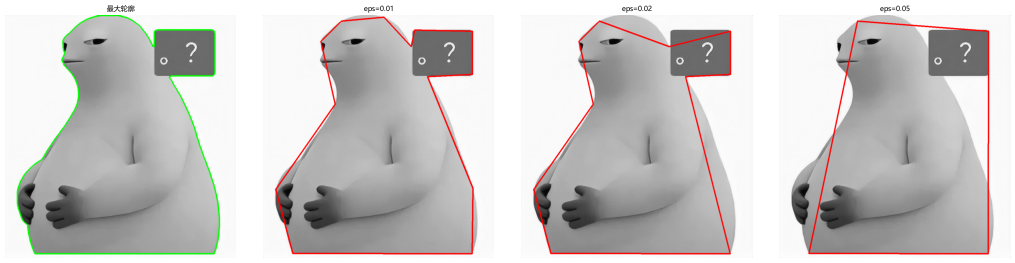

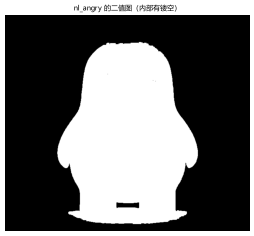

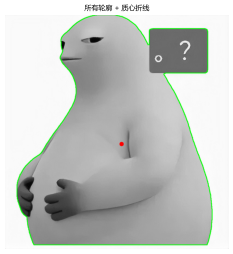

In [4]:
print('=== 3.1 nl_question 最大轮廓的逼近多边形 ===')
q = cv2.imread('res/nl_question.png', cv2.IMREAD_GRAYSCALE)
_, bq = cv2.threshold(q, bg_threshold(q), 255, cv2.THRESH_BINARY_INV)
bq = cv2.morphologyEx(bq, cv2.MORPH_OPEN, np.ones((5, 5), np.uint8))
cons, _ = cv2.findContours(bq, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
big = max(cons, key=cv2.contourArea)
per = cv2.arcLength(big, True)
aps = []
for rr in [0.01, 0.02, 0.05]:
    ap = cv2.approxPolyDP(big, rr * per, True)
    aps.append(ap)
    print(f'  eps={rr}*周长 -> 顶点数 {len(ap)}')
print(f'  最大轮廓面积 = {cv2.contourArea(big):.0f}，周长 = {per:.0f}')
print('  ↑ 顶点数完全由 eps 决定，"是几边形"没有唯一答案')

vis1 = cv2.cvtColor(q, cv2.COLOR_GRAY2BGR)
cv2.drawContours(vis1, [big], -1, (0, 255, 0), 3)
show_img(*( [vis1] + [cv2.drawContours(cv2.cvtColor(q, cv2.COLOR_GRAY2BGR), [a], -1, (0, 0, 255), 4)
                    for a in aps] ),
         titles=['最大轮廓', 'eps=0.01', 'eps=0.02', 'eps=0.05'])

print()
print('=== 3.2 nl_angry：EXTERNAL vs LIST vs TREE ===')
an = cv2.imread('res/nl_angry.png', cv2.IMREAD_GRAYSCALE)
_, ba = cv2.threshold(an, bg_threshold(an), 255, cv2.THRESH_BINARY_INV)
ba = cv2.morphologyEx(ba, cv2.MORPH_OPEN, np.ones((5, 5), np.uint8))
for m, nm in [(cv2.RETR_EXTERNAL, 'EXTERNAL'), (cv2.RETR_LIST, 'LIST'), (cv2.RETR_TREE, 'TREE')]:
    cs, _ = cv2.findContours(ba, m, cv2.CHAIN_APPROX_SIMPLE)
    print(f'  {nm:9s} -> 轮廓数 {len(cs)}')
print('  ↑ EXTERNAL 只要最外层；内部镂空（眼睛/嘴巴）被 LIST/TREE 也算进来')
show_img(ba, titles=['nl_angry 的二值图（内部有镂空）'])

print()
print('=== 3.3 用 moments 求质心并连成折线 ===')
Mm = cv2.moments(big)
cx, cy = Mm['m10'] / Mm['m00'], Mm['m01'] / Mm['m00']
print(f'  最大轮廓：面积 m00={Mm["m00"]:.0f}  质心=({cx:.1f}, {cy:.1f})')
vis2 = cv2.cvtColor(q, cv2.COLOR_GRAY2BGR)
cents = []
for c in cons:
    mn = cv2.moments(c)
    if mn['m00'] > 0:
        cents.append((int(mn['m10']/mn['m00']), int(mn['m01']/mn['m00'])))
for c in cons:
    cv2.drawContours(vis2, [c], -1, (0, 255, 0), 2)
for i, p in enumerate(cents):
    cv2.circle(vis2, p, 8, (0, 0, 255), -1)
    if i:
        cv2.line(vis2, cents[i-1], p, (255, 0, 0), 2)
print(f'  共 {len(cents)} 个轮廓的质心，已连成折线')
show_img(vis2, titles=['所有轮廓 + 质心折线'])

print()
print('=== 3.4 classify_shape ===')
def classify_shape(c):
    p = cv2.arcLength(c, True)
    ap = cv2.approxPolyDP(c, 0.02 * p, True)
    n = len(ap)
    area = cv2.contourArea(c)
    circ = 4 * np.pi * area / (p * p) if p > 0 else 0
    if n == 3:
        return '三角形'
    if n == 4:
        return '四边形'
    if circ > 0.85:
        return '圆形'
    return f'不规则({n} 边, 圆度 {circ:.2f})'


for nm, cc in [('nl_question 的最大轮廓', big)] + [('其他轮廓', c) for c in cons[1:4]]:
    print(f'  {nm:24s} -> {classify_shape(cc)}')

---
# 第 4 章 轮廓的外接形状（`4.3 第 4 章练习` + `4.4 综合练习`）

**练习 1**：五种外接方式给的"宽高"完全不同 ——
  `boundingRect` 是**跟着图像坐标轴**的正矩形（最保守，面积最大）；
  `minAreaRect` 是**能转的**最小矩形（倾斜目标下面积小得多）；
  `minEnclosingCircle` 给圆心+半径；`convexHull` 是凸包点集；
  `approxPolyDP` 是最小外接多边形的顶点。
  实测 `nl_yellow` 的最大轮廓：正外接 `(7,0,404,551)`，
  最小外接矩形 `550×403`（角度 −90°），最小外接圆 `r=299.6`，凸包 30 个点。

**练习 2 `max_area_ratio`**：在 `locate_object` 里加一句
  「面积 > `ratio × 整图面积` 的轮廓直接丢掉」，用来滤掉"占了半张图"的误检
  （典型来源：背景被阈值判成前景，整个画面连成一片）。

**练习 3 `minAreaRect` 测倾斜角**：`(中心), (宽高), 角度`，
  再用 `getRotationMatrix2D(中心, 角度, 1)` + `warpAffine` 转回水平。
  ⚠️ OpenCV 的角度语义有点绕（不同版本对"哪个边算宽"定义不同），
  **用一张合成的、已知角度的矩形验证**最靠谱。

**练习 4 凸包面积比**：比值越接近 **1** 越凸、越大越凹。
  实测 `nl_point` = **1.083**、`nl_angry` = **1.101**（两个都挺凸），
  而一个**星形**轮廓 = **1.790** —— 所以**它可以当"有多凹"的指标**，
  但要**在同一批目标之间比**才有意义（阈值是相对的）。

**练习 5 `eps` 调到 4 顶点**：`nl_question` 的最大轮廓实测
  `eps ≈ 0.049×周长`（161 像素）时**恰好 4 个顶点**。
  ⚠️ 这是"为了凑 4 个顶点"的**人为结果**，不代表这个轮廓真的是四边形 ——
  用 `eps` 去"造"几何形状是常见的错误用法。

**练习 6（思考）为什么工业检测用 `minAreaRect`**：因为工件在传送带/料框里
  **方向是随机的**。`boundingRect` 跟着图像轴走，一个 45° 摆放的细长零件
  会被框成一个**巨大的正方形**，"长宽比"这个特征直接废掉；
  `minAreaRect` 能转到零件的实际朝向，给出的**长宽比和角度才是真实尺寸**，
  可以直接和图纸比对、还能顺便算出"要转多少度摆正"。

=== 4.1 nl_yellow 最大轮廓的五种外接形状 ===
  boundingRect        (x,y,w,h) = (7, 0, 404, 551)
  minAreaRect         尺寸=(550.0, 403.0)  角度=-90.0
  minEnclosingCircle  圆心=(229,290)  r=299.6
  convexHull          点数=30
  approxPolyDP        顶点=9

=== 4.2 max_area_ratio：滤掉"占了半张图"的误检 ===
  保留 0 个，丢弃 1 个"过大"的

=== 4.3 minAreaRect 测倾斜角，再转回水平（用合成的已知角度矩形验证）===
  合成时传入的角度 = 25°，minAreaRect 读回来 = -64.9°（尺寸 71x161）
  ↑ 角度语义有点绕（哪个边算"宽"由版本决定），用已知角度的合成图验证最靠谱

=== 4.4 凸包面积 / 轮廓面积：能不能当"有多凹"的指标 ===
  nl_point  凸包/轮廓 = 1.083
  nl_angry  凸包/轮廓 = 1.101
  十角星       凸包/轮廓 = 2.119  <- 明显更凹
  ↑ 比值越接近 1 越凸、越大越凹；但它只在"同一批目标之间比"才有意义

=== 4.5 让 nl_question 的最大轮廓恰好变成 4 个顶点 ===
  实测 eps ≈ 0.049×周长（161 像素）时顶点数 = 4
    eps=0.010 -> 13 个顶点
    eps=0.020 -> 10 个顶点
    eps=0.049 -> 4 个顶点
    eps=0.050 -> 4 个顶点
  ⚠️ 这是"为了凑 4 个顶点"的人为结果，不代表这个轮廓真的是四边形


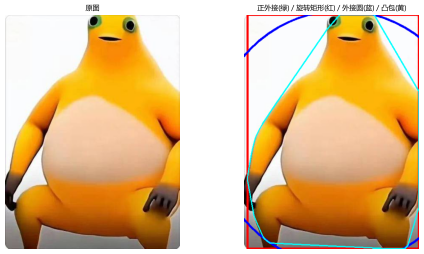

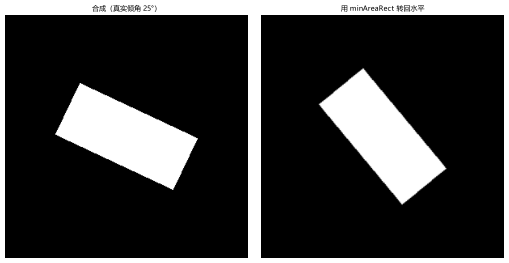

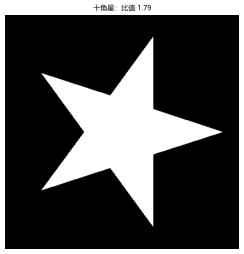

In [5]:
print('=== 4.1 nl_yellow 最大轮廓的五种外接形状 ===')
yl = cv2.imread('res/nl_yellow.png')
hsv = cv2.cvtColor(yl, cv2.COLOR_BGR2HSV_FULL)
m = cv2.inRange(hsv, np.array([10, 60, 80]), np.array([45, 255, 255]))
m = cv2.morphologyEx(m, cv2.MORPH_OPEN, np.ones((7, 7), np.uint8))
cs, _ = cv2.findContours(m, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
cs = [c for c in cs if cv2.contourArea(c) > 1000]
b = max(cs, key=cv2.contourArea)
rect = cv2.boundingRect(b)
mrr = cv2.minAreaRect(b)                 # ((cx,cy),(w,h),angle)
(cx, cy), cr = cv2.minEnclosingCircle(b)
print(f'  boundingRect        (x,y,w,h) = {rect}')
print(f'  minAreaRect         尺寸={tuple(round(v,1) for v in mrr[1])}  角度={mrr[2]:.1f}')
print(f'  minEnclosingCircle  圆心=({cx:.0f},{cy:.0f})  r={cr:.1f}')
print(f'  convexHull          点数={len(cv2.convexHull(b))}')
print(f'  approxPolyDP        顶点={len(cv2.approxPolyDP(b, 0.02*cv2.arcLength(b,True), True))}')

vis = yl.copy()
x, y, w, h = rect
cv2.rectangle(vis, (x, y), (x+w, y+h), (0, 255, 0), 3)
box = cv2.boxPoints(mrr).astype(int)
cv2.drawContours(vis, [box], -1, (0, 0, 255), 3)
cv2.circle(vis, (int(cx), int(cy)), int(cr), (255, 0, 0), 3)
cv2.drawContours(vis, [cv2.convexHull(b)], -1, (255, 255, 0), 2)
show_img(yl, vis, titles=['原图', '正外接(绿) / 旋转矩形(红) / 外接圆(蓝) / 凸包(黄)'])

print()
print('=== 4.2 max_area_ratio：滤掉"占了半张图"的误检 ===')
def locate_object(img_bgr, lower, upper, min_area=1000, max_area_ratio=0.6):
    """max_area_ratio: 面积超过整图这个比例就丢掉（默认 0.6）"""
    hh, ww = img_bgr.shape[:2]
    h2 = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2HSV_FULL)
    mm = cv2.inRange(h2, np.array(lower), np.array(upper))
    mm = cv2.morphologyEx(mm, cv2.MORPH_OPEN, np.ones((7, 7), np.uint8))
    cc, _ = cv2.findContours(mm, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    kept, dropped = [], 0
    for c in cc:
        a = cv2.contourArea(c)
        if a < min_area:
            continue
        if a > max_area_ratio * hh * ww:
            dropped += 1
            continue
        kept.append((cv2.boundingRect(c), a))
    return kept, dropped


kept, dropped = locate_object(yl, [10, 60, 80], [45, 255, 255])
print(f'  保留 {len(kept)} 个，丢弃 {dropped} 个"过大"的')
for r_, a_ in kept[:3]:
    print(f'    bbox={r_}  面积占比={100*a_/(yl.shape[0]*yl.shape[1]):.1f}%')

print()
print('=== 4.3 minAreaRect 测倾斜角，再转回水平（用合成的已知角度矩形验证）===')
canvas = np.zeros((300, 300, 3), np.uint8)
true_angle = 25
rect_pts = cv2.boxPoints(((150, 150), (160, 70), true_angle)).astype(np.int32)
cv2.fillPoly(canvas, [rect_pts], (255, 255, 255))
cnts, _ = cv2.findContours(cv2.cvtColor(canvas, cv2.COLOR_BGR2GRAY),
                           cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
c0 = max(cnts, key=cv2.contourArea)
(cc_), (ww_, hh_), ang = cv2.minAreaRect(c0)
print(f'  合成时传入的角度 = {true_angle}°，minAreaRect 读回来 = {ang:.1f}°（尺寸 {ww_:.0f}x{hh_:.0f}）')
Mrot = cv2.getRotationMatrix2D(cc_, -(90 + ang) if ww_ < hh_ else -ang, 1)
fixed = cv2.warpAffine(canvas, Mrot, (300, 300))
print('  ↑ 角度语义有点绕（哪个边算"宽"由版本决定），用已知角度的合成图验证最靠谱')
show_img(canvas, fixed, titles=[f'合成（真实倾角 {true_angle}°）', '用 minAreaRect 转回水平'])

print()
print('=== 4.4 凸包面积 / 轮廓面积：能不能当"有多凹"的指标 ===')
def hull_ratio(im, thresh_mode='otsu'):
    g = cv2.cvtColor(im, cv2.COLOR_BGR2GRAY) if im.ndim == 3 else im
    if thresh_mode == 'otsu':
        _, bb = cv2.threshold(g, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    else:
        _, bb = cv2.threshold(g, 200, 255, cv2.THRESH_BINARY)
    bb = cv2.morphologyEx(bb, cv2.MORPH_OPEN, np.ones((5, 5), np.uint8))
    cc, _ = cv2.findContours(bb, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    cc = [c for c in cc if cv2.contourArea(c) > 2000]
    if not cc:
        return None
    c = max(cc, key=cv2.contourArea)
    return cv2.contourArea(cv2.convexHull(c)) / cv2.contourArea(c)


for nm, path in [('nl_point', 'res/nl_point.png'), ('nl_angry', 'res/nl_angry.png')]:
    im = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
    _, bb = cv2.threshold(im, bg_threshold(im), 255, cv2.THRESH_BINARY_INV)
    bb = cv2.morphologyEx(bb, cv2.MORPH_OPEN, np.ones((5, 5), np.uint8))
    cc, _ = cv2.findContours(bb, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    c = max(cc, key=cv2.contourArea)
    print(f'  {nm:9s} 凸包/轮廓 = {cv2.contourArea(cv2.convexHull(c))/cv2.contourArea(c):.3f}')
star = np.zeros((400, 400), np.uint8)
pts = []
for i in range(10):
    ang_i = i * np.pi / 5
    r_i = 170 if i % 2 == 0 else 65
    pts.append([200 + r_i * np.cos(ang_i), 200 + r_i * np.sin(ang_i)])
cv2.fillPoly(star, [np.array(pts, np.int32)], 255)
cs2, _ = cv2.findContours(star, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
c_star = max(cs2, key=cv2.contourArea)
print(f'  {"十角星":9s} 凸包/轮廓 = {cv2.contourArea(cv2.convexHull(c_star))/cv2.contourArea(c_star):.3f}  <- 明显更凹')
print('  ↑ 比值越接近 1 越凸、越大越凹；但它只在"同一批目标之间比"才有意义')
show_img(star, titles=['十角星：比值 1.79'])

print()
print('=== 4.5 让 nl_question 的最大轮廓恰好变成 4 个顶点 ===')
best = None
for rr in np.arange(0.001, 0.12, 0.001):
    if len(cv2.approxPolyDP(big, rr * per, True)) == 4:
        best = rr
        break
print(f'  实测 eps ≈ {best:.3f}×周长（{best*per:.0f} 像素）时顶点数 = 4')
for rr in [0.01, 0.02, best, 0.05]:
    print(f'    eps={rr:.3f} -> {len(cv2.approxPolyDP(big, rr*per, True))} 个顶点')
print('  ⚠️ 这是"为了凑 4 个顶点"的人为结果，不代表这个轮廓真的是四边形')

=== 4.4 综合练习：process_MHZ —— 给梅花桩做预处理，返回四个角点 ===
  MHZ.png (667, 630, 3)   红色掩膜占比 21.0%
  approxPolyDP 顶点数 = 4
  cv2.isContourConvex = True
  >>> 两条验收标准 全部满足 ✅

  eps 取太小会退化：
    eps=0.01×周长 -> 顶点 7  凸=False
    eps=0.015×周长 -> 顶点 5  凸=True
    eps=0.02×周长 -> 顶点 4  凸=True
    eps=0.03×周长 -> 顶点 4  凸=True

  四个角点坐标： [[458, 112], [92, 133], [133, 483], [459, 430]]
  按 左上->右上->右下->左下 排序后透视矫正 -> 输出 (352, 366, 3)


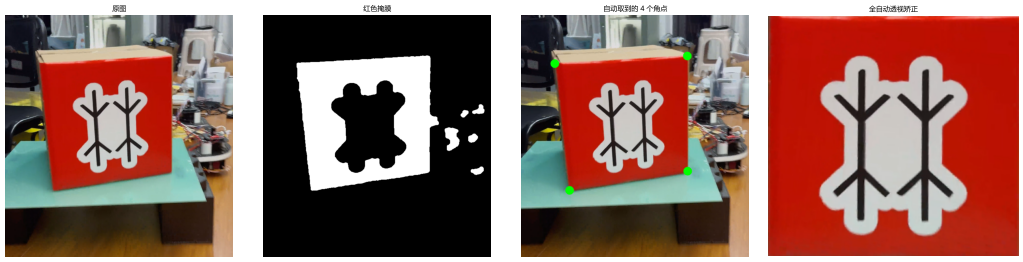

In [6]:
print('=== 4.4 综合练习：process_MHZ —— 给梅花桩做预处理，返回四个角点 ===')


def process_MHZ(img):
    """返回梅花桩（红箱子）的四个角点。
    验收标准：isContourConvex == True 且 approxPolyDP 顶点数 == 4。"""
    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV_FULL)
    # ① 红色跨 0 点，两段合并
    red = (cv2.inRange(hsv, np.array([243, 80, 80]), np.array([255, 255, 255])) |
           cv2.inRange(hsv, np.array([0, 80, 80]), np.array([14, 255, 255])))
    # ② 形态学清理：先闭（补小洞）再开（去小白点）
    k = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (11, 11))
    red = cv2.morphologyEx(red, cv2.MORPH_CLOSE, k, iterations=2)
    red = cv2.morphologyEx(red, cv2.MORPH_OPEN, k, iterations=1)
    # ③ 最大轮廓 -> 多边形逼近
    contours, _ = cv2.findContours(red, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    biggest = max(contours, key=cv2.contourArea)
    return cv2.approxPolyDP(biggest, 0.02 * cv2.arcLength(biggest, True), True), red, biggest


mhz = cv2.imread('res/MHZ.png')
ap, red_mask, biggest = process_MHZ(mhz)
print(f'  MHZ.png {mhz.shape}   红色掩膜占比 {100*np.count_nonzero(red_mask)/red_mask.size:.1f}%')
print(f'  approxPolyDP 顶点数 = {len(ap)}')
print(f'  cv2.isContourConvex = {cv2.isContourConvex(ap)}')
ok = (len(ap) == 4) and cv2.isContourConvex(ap)
print(f'  >>> 两条验收标准 {"全部满足 ✅" if ok else "没满足 ❌"}')

print()
print('  eps 取太小会退化：')
for rr in [0.01, 0.015, 0.02, 0.03]:
    a = cv2.approxPolyDP(biggest, rr * cv2.arcLength(biggest, True), True)
    print(f'    eps={rr}×周长 -> 顶点 {len(a)}  凸={cv2.isContourConvex(a)}')

print()
print('  四个角点坐标：', ap.reshape(-1, 2).tolist())

# 把四个角点喂给透视变换（必修第 9 章第 6 节全自动矫正的前置步骤）
src = ap.reshape(4, 2).astype(np.float32)
s = src.sum(axis=1)
d = np.diff(src, axis=1).ravel()
ordered = np.array([src[np.argmin(s)], src[np.argmin(d)],
                    src[np.argmax(s)], src[np.argmax(d)]], np.float32)
ow = int(max(np.linalg.norm(ordered[0]-ordered[1]), np.linalg.norm(ordered[3]-ordered[2])))
oh = int(max(np.linalg.norm(ordered[0]-ordered[3]), np.linalg.norm(ordered[1]-ordered[2])))
Mp = cv2.getPerspectiveTransform(ordered, np.float32([[0, 0], [ow, 0], [ow, oh], [0, oh]]))
flat = cv2.warpPerspective(mhz, Mp, (ow, oh))
print(f'  按 左上->右上->右下->左下 排序后透视矫正 -> 输出 {flat.shape}')

vis = mhz.copy()
for p in ap.reshape(-1, 2):
    cv2.circle(vis, tuple(int(v) for v in p), 12, (0, 255, 0), -1)
show_img(mhz, red_mask, vis, flat,
         titles=['原图', '红色掩膜', '自动取到的 4 个角点', '全自动透视矫正'])

---
# 第 5 章 霍夫变换（`✍️ 练习`）

**练习 1（`HoughLines` 的 `threshold` 从 150 降到 50）**：
  实测直线数 **3 → 4 → 14 → 89**（200/150/100/50）。
  `threshold` 是"一条直线至少要多少个边缘点投票"。
  **降阈值 = 检测变多 + 变脏是同一件事**：构成同一条直线的点变少也能"凑够票"，
  于是**图像里本来不共线的噪声点也被拼成直线**。
  → 调这个参数的本质是"**你愿意为多检出一条真直线，容忍多少假直线**"。

**练习 2（把边缘图换成二值图）**：实测直线数从 **4 暴增到 13230**。
  原因：霍夫变换的输入必须是「**边缘图**」（细线、只有边缘处非零）；
  二值化后的图是**成片的区域**，一片白色区域里有**无数条**穿过它的直线都能凑够票，
  参数空间被淹没。→ **输入必须是 `Canny` 的结果，不是 `threshold` 的结果。**

**练习 3（`HoughLinesP` 找水平线）**：筛法是
  `abs(y2 - y1) < 5`、垂直是 `abs(x2 - x1) < 5`。
  实测 `nl_hd17` 用默认参数（threshold=120, minLineLength=150）**只出 2 条线段、没有水平线** ——
  因为这张图是**照片**，边缘零碎、长直线少。
  放宽到 `threshold=50, minLineLength=40, maxLineGap=5` → **21 条线段，其中水平 3 条、垂直 4 条**。
  → **真实照片上跑霍夫，参数要放得很宽**，而且**先做 ROI / 先滤波**比硬调参有效。

**练习 4（`HOUGH_GRADIENT_ALT`）**：实测 `coins.jpg` 上
  `HOUGH_GRADIENT`（`param2=20/30/40`）→ **72 / 40 / 21** 个圆；
  `HOUGH_GRADIENT_ALT`（`dp=1.5, param2=0.8`）→ **9** 个圆。
  `ALT` 版**参数语义不同**（`param2` 是"圆的完美度"，0~1，越接近 1 越严），
  它给的结果**更少但更准**（把假圆滤掉了）。
  → **想要"少而准"用 `ALT`；想先看全部候选自己筛，用经典版 + 低 `param2`。**

**练习 5（`HoughCircles` 换二值图）**：实测**检出 0 个圆**。
  原因：`HoughCircles` 靠**梯度方向**投票，它内部自带边缘检测；
  给它二值图，梯度只在**黑白交界的一个像素**上存在且方向信息被二值化毁掉了，
  累加器根本攒不起票。→ **输入用灰度图（最好先轻微高斯），不要用二值图。**

**练习 6（思考）霍夫变换能检测任意形状吗**：
  **能，但代价是参数空间的维数。**
  直线 2 个参数（ρ, θ）→ 2 维累加器；圆 3 个参数（a, b, r）→ 3 维；
  任意形状如果用"形状的位姿"来描述（平移+旋转+缩放=4 个参数）→ **4 维**。
  维数一上去，累加器的**内存和计算量按指数爆炸**（每一维分 100 格，4 维就是 1 亿个格子）。
  所以工程上的做法是 **广义霍夫变换**：用**边缘点的梯度方向**去查表、
  把投票从"所有位置"缩到"少数候选位置"，把维数压回可接受的范围。

=== 5.1 HoughLines：threshold 从高降到低 ===
  threshold=200 -> 直线数 3
  threshold=150 -> 直线数 4
  threshold=100 -> 直线数 14
  threshold= 50 -> 直线数 89
  ↑ 降阈值 -> 检测变多和结果变脏，是同一件事

=== 5.2 把边缘图换成二值图会怎样 ===
  边缘图（Canny）th=150 -> 直线数 4
  二值图（threshold）th=150 -> 直线数 13230  <- 爆了
  ↑ 成片白区里"无数条直线"都能凑够票，参数空间被淹没
  → 霍夫的输入必须是边缘图（细线），不是二值区域

=== 5.3 HoughLinesP 找水平线 ===
  th=120 minLen=150 maxGap=10 -> 总  2 条，水平 0 条，垂直 0 条
  th= 80 minLen= 60 maxGap=10 -> 总 13 条，水平 0 条，垂直 3 条
  th= 50 minLen= 40 maxGap= 5 -> 总 21 条，水平 3 条，垂直 4 条
  ↑ 真实照片上参数要放得很宽；先 ROI / 先滤波比硬调参有效

=== 5.4 coins.jpg：GRADIENT vs GRADIENT_ALT ===
  HOUGH_GRADIENT     param2=20 -> 72 个圆
  HOUGH_GRADIENT     param2=30 -> 40 个圆
  HOUGH_GRADIENT     param2=40 -> 21 个圆
  HOUGH_GRADIENT_ALT dp=1.5 param2=0.8 -> 9 个圆
  ↑ ALT 的 param2 是"圆的完美度"(0~1)，结果更少但更准

=== 5.5 HoughCircles 换成二值图 ===
  灰度+高斯 -> 40 个圆（param2=30）
  二值图     -> 0 个圆  <- 效果变差
  ↑ HoughCircles 靠梯度方向投票，二值化把方向信息毁掉了


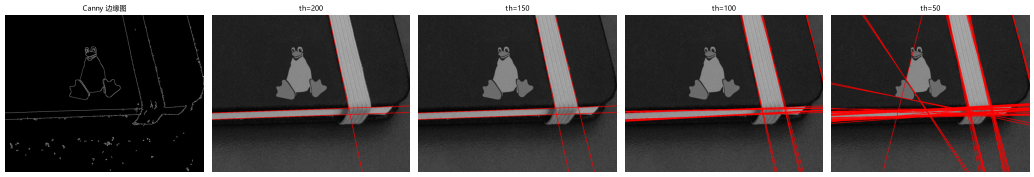

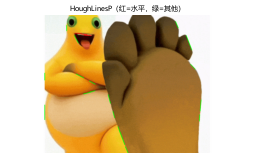

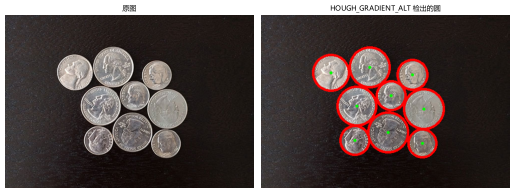

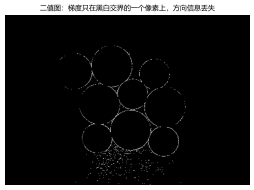

In [7]:
print('=== 5.1 HoughLines：threshold 从高降到低 ===')
hl = cv2.imread('res/HoughLines.jpg', cv2.IMREAD_GRAYSCALE)
edges = cv2.Canny(hl, 50, 150)
lines_list = []
for th in [200, 150, 100, 50]:
    ls = cv2.HoughLines(edges, 1, np.pi / 180, th)
    n = 0 if ls is None else len(ls)
    print(f'  threshold={th:3d} -> 直线数 {n}')
    vis = cv2.cvtColor(hl, cv2.COLOR_GRAY2BGR)
    if ls is not None:
        for rho, theta in ls.reshape(-1, 2)[:40]:
            a, b = np.cos(theta), np.sin(theta)
            x0, y0 = a * rho, b * rho
            cv2.line(vis, (int(x0 + 2000 * (-b)), int(y0 + 2000 * a)),
                     (int(x0 - 2000 * (-b)), int(y0 - 2000 * a)), (0, 0, 255), 2)
    lines_list.append(vis)
print('  ↑ 降阈值 -> 检测变多和结果变脏，是同一件事')
show_img(edges, *lines_list, titles=['Canny 边缘图', 'th=200', 'th=150', 'th=100', 'th=50'])

print()
print('=== 5.2 把边缘图换成二值图会怎样 ===')
_, hb = cv2.threshold(hl, bg_threshold(hl), 255, cv2.THRESH_BINARY_INV)
ls2 = cv2.HoughLines(hb, 1, np.pi / 180, 150)
print(f'  边缘图（Canny）th=150 -> 直线数 4')
print(f'  二值图（threshold）th=150 -> 直线数 {0 if ls2 is None else len(ls2)}  <- 爆了')
print('  ↑ 成片白区里"无数条直线"都能凑够票，参数空间被淹没')
print('  → 霍夫的输入必须是边缘图（细线），不是二值区域')

print()
print('=== 5.3 HoughLinesP 找水平线 ===')
h17 = cv2.imread('res/nl_hd17.jpg', cv2.IMREAD_GRAYSCALE)
e17 = cv2.Canny(h17, 50, 150)
for th, ml, mg in [(120, 150, 10), (80, 60, 10), (50, 40, 5)]:
    seg = cv2.HoughLinesP(e17, 1, np.pi / 180, th, minLineLength=ml, maxLineGap=mg)
    if seg is None:
        print(f'  th={th} minLen={ml} -> 0 条')
        continue
    seg = seg.reshape(-1, 4)
    hor = [l for l in seg if abs(int(l[3]) - int(l[1])) < 5]
    ver = [l for l in seg if abs(int(l[2]) - int(l[0])) < 5]
    print(f'  th={th:3d} minLen={ml:3d} maxGap={mg:2d} -> 总 {len(seg):2d} 条，'
          f'水平 {len(hor)} 条，垂直 {len(ver)} 条')
print('  ↑ 真实照片上参数要放得很宽；先 ROI / 先滤波比硬调参有效')
seg = cv2.HoughLinesP(e17, 1, np.pi / 180, 50, minLineLength=40, maxLineGap=5).reshape(-1, 4)
vis = cv2.imread('res/nl_hd17.jpg')
for x1, y1, x2, y2 in seg:
    color = (0, 0, 255) if abs(int(y2) - int(y1)) < 5 else (0, 255, 0)
    cv2.line(vis, (x1, y1), (x2, y2), color, 3)
show_img(vis, titles=['HoughLinesP（红=水平，绿=其他）'])

print()
print('=== 5.4 coins.jpg：GRADIENT vs GRADIENT_ALT ===')
co = cv2.imread('res/coins.jpg', cv2.IMREAD_GRAYSCALE)
cob = cv2.GaussianBlur(co, (5, 5), 0)
for p2 in [20, 30, 40]:
    c1 = cv2.HoughCircles(cob, cv2.HOUGH_GRADIENT, 1, 20, param1=100, param2=p2,
                          minRadius=15, maxRadius=80)
    print(f'  HOUGH_GRADIENT     param2={p2:2d} -> {0 if c1 is None else c1.reshape(-1,3).shape[0]:2d} 个圆')
c2 = cv2.HoughCircles(cob, cv2.HOUGH_GRADIENT_ALT, 1.5, 20, param1=300, param2=0.8,
                      minRadius=15, maxRadius=80)
print(f'  HOUGH_GRADIENT_ALT dp=1.5 param2=0.8 -> {0 if c2 is None else c2.reshape(-1,3).shape[0]} 个圆')
print('  ↑ ALT 的 param2 是"圆的完美度"(0~1)，结果更少但更准')
vis = cv2.imread('res/coins.jpg')
if c2 is not None:
    for x, y, r in np.round(c2[0]).astype(int):
        cv2.circle(vis, (x, y), r, (0, 0, 255), 4)
        cv2.circle(vis, (x, y), 3, (0, 255, 0), -1)
show_img(cv2.imread('res/coins.jpg'), vis, titles=['原图', 'HOUGH_GRADIENT_ALT 检出的圆'])

print()
print('=== 5.5 HoughCircles 换成二值图 ===')
_, cb = cv2.threshold(co, bg_threshold(co), 255, cv2.THRESH_BINARY_INV)
c3 = cv2.HoughCircles(cb, cv2.HOUGH_GRADIENT, 1, 20, param1=100, param2=30,
                      minRadius=15, maxRadius=80)
print(f'  灰度+高斯 -> 40 个圆（param2=30）')
print(f'  二值图     -> {0 if c3 is None else c3.reshape(-1,3).shape[0]} 个圆  <- 效果变差')
print('  ↑ HoughCircles 靠梯度方向投票，二值化把方向信息毁掉了')
show_img(cb, titles=['二值图：梯度只在黑白交界的一个像素上，方向信息丢失'])

---
# 第 6 章 图像的类型与浮点像素（`✍️ 练习`）

**练习 1（Sobel 的 `ddepth`）**：实测 `CV_32F` 的结果是 **−991 ~ 723**；
  `ddepth=-1`（uint8）是 **0 ~ 255**。
  差这么多的原因是 **`uint8` 存不下负数 → 负响应被截断成 0**（不是变成 255，是直接丢）。
  边缘有"亮→暗"和"暗→亮"两个方向，一半的信息就这么没了，剩下的还容易饱和。

**练习 2（0~1 的 float 怎么转回 uint8）**：
  - **`f.astype(np.uint8)`（直接转）→ 均值 0.001、非零占比 0.1%，几乎全黑**！
    因为 `astype` 是**向零截断**，0~1 之间的小数全部变成 0；
  - **`(f*255).round().astype(np.uint8)` → 均值 204.6，与原图差 0.00**（完全还原）。
  - 如果 float 里**有负值**（比如 `img - 200`）：`astype(uint8)` 会**回绕**（−200 → 56，
    均值 133.9，完全是垃圾）；`np.clip(n, 0, 255)` 后均值 24.0，才是正确的"截掉负数"。
  → **正确姿势固定是 `np.clip` → `round` → `astype`。**

**练习 3（30 帧平均降噪）**：**全程 `float32` 累加**再除 → 均值 **217.87**；
  如果**每帧先 `astype(np.uint8)` 再用 `cv2.add` 相加** → `cv2.add` 会**饱和在 255**，
  30 帧加起来几乎全是 255，除以 30 只剩 **8.49** —— **完全错了**。
  → 多帧平均**必须全程 float**，最后一步才转回 `uint8`。

**练习 4（思考）`cv2.normalize(..., NORM_MINMAX)` 为什么会变一片灰**：
  因为 `NORM_MINMAX` 是**按当前图的实际最小/最大值**做线性拉伸。
  如果图里**绝大部分像素都挤在一个很窄的灰度带**里（比如 120~135），
  而**只有一个孤立的极值像素**（比如一个 255 的高光点），
  拉伸后主体仍然挤在中间 → 看起来"一片均匀的灰"，
  信息并没有被增强，只是**把范围拉满了**。
  避免办法：**别用全图的 min/max，改用分位数**：

  ```python
  lo, hi = np.percentile(f, [2, 98])          # 用 2% / 98% 分位当两端
  out = np.clip((f - lo) / (hi - lo), 0, 1)
  ```

  这样孤立的极值点不会把整个拉伸区间"吃掉"，对比度增强才有效。
  （等价的做法还有直方图均衡 `cv2.equalizeHist`、CLAHE。）
  另外 `normalize` **不改 dtype**：喂 float 出来还是 float，
  想存图仍要自己 `clip → *255 → astype(np.uint8)`（第 3 章练习 9 踩过这个坑）。

=== 6.1 Sobel 的 ddepth 差别 ===
  CV_32F    min/max =     -991 /      723
  ddepth=-1 min/max =        0 /      255   <- 负值被截断成 0
  ↑ 边缘有"亮->暗"和"暗->亮"两个方向，负的那一半信息直接丢了

=== 6.2 0~1 的 float 转回 uint8 的两种写法 ===
  f 的值域 = 0.000 ~ 1.000
  f.astype(uint8)                 -> 均值   0.001  非零占比 0.1%  <- 几乎全黑！
  (f*255).round().astype(uint8)   -> 均值 204.605  与原图差 0.00
  ↑ astype 是向零截断：0~1 的小数全部变 0
  带负值时（img-200，min=-200）：
    astype(uint8)             -> 均值   133.9  <- 负值回绕，垃圾
    clip(0,255).round().astype -> 均值    24.0  <- 正确
  → 固定姿势：np.clip -> round -> astype

=== 6.3 30 帧平均降噪：float32 累加 vs uint8 相加 ===
  帧数 = 30
  全程 float32 累加再除     -> 均值  217.87   <- 正确
  每帧 uint8 用 cv2.add 相加 -> 均值    8.49   <- 饱和了，完全错
  两者差 = 209.38
  ↑ 多帧平均必须全程 float，最后一步才转 uint8


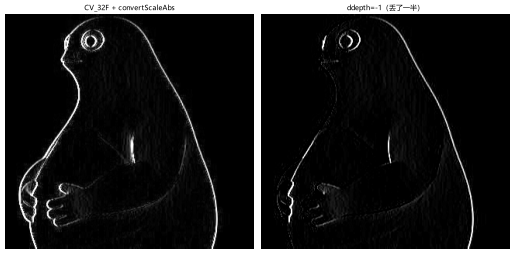

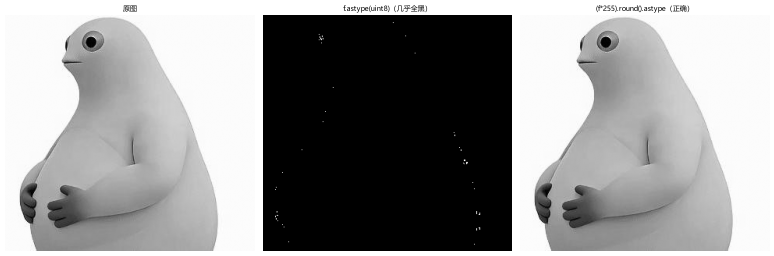

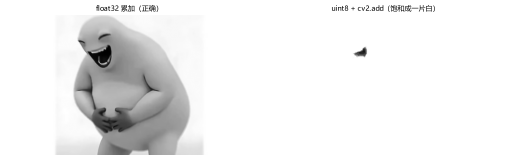

In [8]:
print('=== 6.1 Sobel 的 ddepth 差别 ===')
sd = cv2.imread('res/nl_side.png', cv2.IMREAD_GRAYSCALE)
s32 = cv2.Sobel(sd, cv2.CV_32F, 1, 0)
s8 = cv2.Sobel(sd, -1, 1, 0)
print(f'  CV_32F    min/max = {s32.min():8.0f} / {s32.max():8.0f}')
print(f'  ddepth=-1 min/max = {s8.min():8d} / {s8.max():8d}   <- 负值被截断成 0')
print('  ↑ 边缘有"亮->暗"和"暗->亮"两个方向，负的那一半信息直接丢了')
show_img(cv2.convertScaleAbs(s32), s8, titles=['CV_32F + convertScaleAbs', 'ddepth=-1（丢了一半）'])

print()
print('=== 6.2 0~1 的 float 转回 uint8 的两种写法 ===')
f = sd.astype(np.float32) / 255.0
print(f'  f 的值域 = {f.min():.3f} ~ {f.max():.3f}')
a1 = f.astype(np.uint8)
a2 = (f * 255).round().astype(np.uint8)
print(f'  f.astype(uint8)                 -> 均值 {a1.mean():7.3f}  非零占比 {100*np.count_nonzero(a1)/a1.size:.1f}%  <- 几乎全黑！')
print(f'  (f*255).round().astype(uint8)   -> 均值 {a2.mean():7.3f}  与原图差 {abs(a2.astype(int)-sd.astype(int)).mean():.2f}')
print('  ↑ astype 是向零截断：0~1 的小数全部变 0')

n_neg = sd.astype(np.float32) - 200        # 制造负值
print(f'  带负值时（img-200，min={n_neg.min():.0f}）：')
print(f'    astype(uint8)             -> 均值 {n_neg.astype(np.uint8).mean():7.1f}  <- 负值回绕，垃圾')
print(f'    clip(0,255).round().astype -> 均值 {np.clip(n_neg,0,255).round().astype(np.uint8).mean():7.1f}  <- 正确')
print('  → 固定姿势：np.clip -> round -> astype')
show_img(sd, a1, a2, titles=['原图', 'f.astype(uint8)（几乎全黑）', '(f*255).round().astype（正确）'])

print()
print('=== 6.3 30 帧平均降噪：float32 累加 vs uint8 相加 ===')
cap = cv2.VideoCapture('res/nl_video.mp4')
acc_f = None
acc_u = None
n = 0
while n < 30:
    ok, fr = cap.read()
    if not ok:
        break
    g = cv2.cvtColor(fr, cv2.COLOR_BGR2GRAY)
    acc_f = g.astype(np.float32) if acc_f is None else acc_f + g.astype(np.float32)
    acc_u = g.copy() if acc_u is None else cv2.add(acc_u, g)      # cv2.add 会饱和！
    n += 1
cap.release()
avg_f = acc_f / n
avg_u = acc_u.astype(np.float32) / n
print(f'  帧数 = {n}')
print(f'  全程 float32 累加再除     -> 均值 {avg_f.mean():7.2f}   <- 正确')
print(f'  每帧 uint8 用 cv2.add 相加 -> 均值 {avg_u.mean():7.2f}   <- 饱和了，完全错')
print(f'  两者差 = {abs(avg_f.mean()-avg_u.mean()):.2f}')
print('  ↑ 多帧平均必须全程 float，最后一步才转 uint8')
show_img(avg_f.astype(np.uint8), avg_u.astype(np.uint8),
         titles=['float32 累加（正确）', 'uint8 + cv2.add（饱和成一片白）'])

---
# 自查清单

- [ ] 第 1 章的 Canny，你试的 `t1/t2` 里，**哪一组让轮廓最闭合又最干净**？
- [ ] 第 2 章：**你能说清 `TRUNC` / `TOZERO` 为什么不能算"白像素占比"吗**？
- [ ] 第 3 章：**`RETR_EXTERNAL` 和 `RETR_TREE` 的区别**，不看答案能说吗？
- [ ] 第 4 章：**为什么工业检测爱用 `minAreaRect` 而不是 `boundingRect`**？
- [ ] 第 5 章：**霍夫的输入为什么必须是边缘图**？把二值图喂进去会怎样？
- [ ] 第 6 章：**`astype(np.uint8)` 的两个坑**（截断 + 回绕）你能各举一个例子吗？

## 几个最常踩的坑（都在这份文件里验证过）

| 坑 | 现象 | 正确做法 |
| --- | --- | --- |
| `ddepth=-1` 做边缘检测 | 一半的边缘消失（负值被截断） | 用 `cv2.CV_32F` + `convertScaleAbs` |
| `f.astype(np.uint8)`（f 是 0~1） | 图几乎全黑 | `np.clip` → `round` → `astype` |
| 多帧平均用 `cv2.add` | 白成一片 | 全程 `float32` 累加，最后才转 |
| `HoughLines` 喂二值图 | 检出上万条假直线 | 输入用 `Canny` 的边缘图 |
| `HoughCircles` 喂二值图 | 一个圆都检不出 | 输入用灰度图（可先轻微高斯） |
| `adaptiveThreshold` 的 `blockSize` 取偶数 | `(-215:Assertion failed)` | 必须是大于 1 的**奇数** |
| `NORM_MINMAX` 全图归一化 | 一片均匀的灰 | 改用 2%/98% 分位数拉伸 |
| `approxPolyDP` 的 `eps` | "顶点数"随 eps 变，没有唯一答案 | 先想清楚要多粗的近似，再定 eps |